# Lab 2 - VGG16 préentraîné pour MNIST

Ce notebook utilise les poids ImageNet préentraînés de VGG16, gèle la majorité du réseau et ajuste le dernier bloc convolutionnel ainsi qu’une tête à 10 classes. Le modèle n’est pas entraîné entièrement depuis zéro. Le meilleur checkpoint est choisi sur validation, puis évalué sur le test.

Dans Kaggle, ajoutez le dataset MNIST via Add Input, choisissez Settings > Accelerator > GPU T4 x2, et activez Internet pour récupérer les poids VGG16 (~528 MB) s’ils ne sont pas en cache.

In [3]:
from pathlib import Path
import os, gzip, shutil, random, json, subprocess, sys
import numpy as np
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torchvision import datasets, transforms
from torchvision.models import vgg16, VGG16_Weights
import matplotlib.pyplot as plt

SEED=42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
if not torch.cuda.is_available(): raise RuntimeError("Activez le GPU dans Kaggle.")
NUM_GPUS=torch.cuda.device_count()
for i in range(NUM_GPUS): print(f"GPU {i}: {torch.cuda.get_device_name(i)}")
if NUM_GPUS < 2: raise RuntimeError("Sélectionnez GPU T4 x2 pour utiliser deux cartes.")

GPU 0: Tesla T4
GPU 1: Tesla T4


## Préparer le dataset MNIST

In [4]:
required=["train-images-idx3-ubyte","train-labels-idx1-ubyte","t10k-images-idx3-ubyte","t10k-labels-idx1-ubyte"]
files=[p for p in Path("/kaggle/input").rglob("*") if p.is_file()]
raw=Path("/kaggle/working/MNIST/raw"); raw.mkdir(parents=True,exist_ok=True)
for name in required:
    found=[p for p in files if p.name in (name,name+".gz")]
    if not found: raise FileNotFoundError(f"{name} absent; ajoutez le dataset MNIST via Add Input.")
    src=found[0]; dst=raw/name
    if src.name.endswith(".gz"):
        with gzip.open(src,"rb") as fi,open(dst,"wb") as fo: shutil.copyfileobj(fi,fo)
    else: shutil.copy2(src,dst)
    print("Préparé:",name)

Préparé: train-images-idx3-ubyte
Préparé: train-labels-idx1-ubyte
Préparé: t10k-images-idx3-ubyte
Préparé: t10k-labels-idx1-ubyte


## Données et paramètres
59 000 images pour entraîner, 1 000 pour valider et les 10 000 images officielles de test pour l’évaluation finale.

In [5]:
TRAIN_SIZE=59000
VAL_SIZE=1000
BATCH_PER_GPU=32
EPOCHS=10
PATIENCE=3
IMAGE_SIZE=96

class MNISTRGB(Dataset):
    def __init__(self, train=True, indices=None):
        self.ds=datasets.MNIST("/kaggle/working",train=train,download=False)
        self.indices=list(range(len(self.ds))) if indices is None else list(indices)
        self.tf=transforms.Compose([
            transforms.Resize((IMAGE_SIZE,IMAGE_SIZE),antialias=True),
            transforms.Normalize((.485,.456,.406),(.229,.224,.225))
        ])
    def __len__(self): return len(self.indices)
    def __getitem__(self,i):
        im,y=self.ds[self.indices[i]]
        return self.tf(transforms.ToTensor()(im).repeat(3,1,1)),int(y)

g=torch.Generator().manual_seed(SEED)
perm=torch.randperm(60000,generator=g).tolist()
val_idx=perm[:VAL_SIZE]; train_idx=perm[VAL_SIZE:VAL_SIZE+TRAIN_SIZE]
train_ds=MNISTRGB(True,train_idx); val_ds=MNISTRGB(True,val_idx); test_ds=MNISTRGB(False)
train_loader=DataLoader(train_ds,batch_size=64,shuffle=True,num_workers=2,pin_memory=True)
val_loader=DataLoader(val_ds,batch_size=64,shuffle=False,num_workers=2,pin_memory=True)
test_loader=DataLoader(test_ds,batch_size=64,shuffle=False,num_workers=2,pin_memory=True)
print(f"Train {len(train_ds)} | validation {len(val_ds)} | test {len(test_ds)}")

Train 59000 | validation 1000 | test 10000


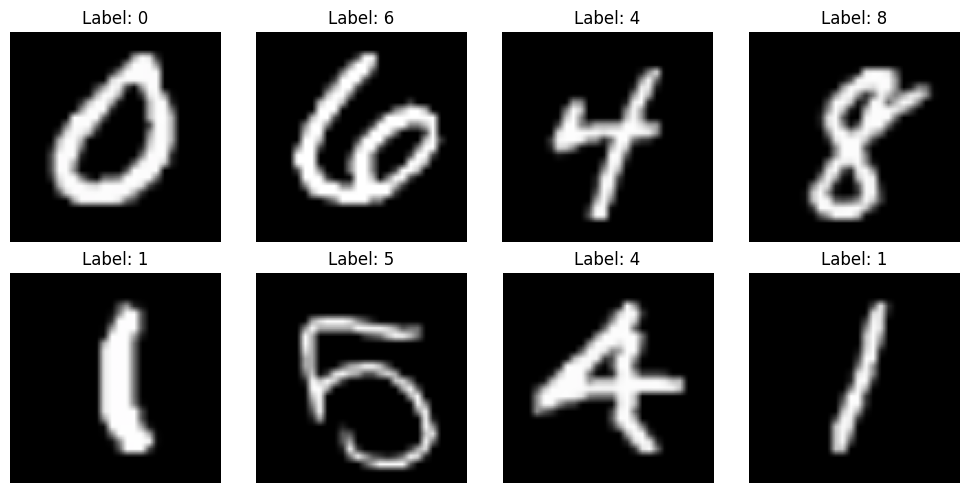

In [6]:
mean=torch.tensor([.485,.456,.406]).view(3,1,1)
std=torch.tensor([.229,.224,.225]).view(3,1,1)
xs,ys=next(iter(train_loader))
fig,axs=plt.subplots(2,4,figsize=(10,5))
for ax,x,y in zip(axs.flat,xs[:8],ys[:8]):
    ax.imshow((x*std+mean).clamp(0,1).permute(1,2,0)); ax.set_title(f"Label: {y.item()}"); ax.axis("off")
plt.tight_layout(); plt.show()

## Charger les poids ImageNet préentraînés
Les poids sont récupérés une fois avant le lancement DDP. Kaggle doit avoir Internet activé s’ils ne sont pas en cache.

In [7]:
try:
    pretrained=vgg16(weights=VGG16_Weights.IMAGENET1K_V1)
except Exception as e:
    raise RuntimeError("Poids VGG16 indisponibles. Activez Internet Kaggle ou ajoutez-les comme input. "+str(e))
pretrained_path="/kaggle/working/vgg16_imagenet_features.pth"
torch.save(pretrained.features.state_dict(),pretrained_path)
del pretrained
print("Poids prêts:",pretrained_path)

Downloading: "https://download.pytorch.org/models/vgg16-397923af.pth" to /root/.cache/torch/hub/checkpoints/vgg16-397923af.pth


100%|██████████| 528M/528M [00:02<00:00, 194MB/s]  


Poids prêts: /kaggle/working/vgg16_imagenet_features.pth


## Fine-tuning sur deux GPU
DDP démarre un processus par carte. La majorité du backbone préentraîné est gelée ; le dernier bloc convolutionnel et la tête à 10 classes sont ajustés. Dropout, weight decay et early stopping limitent le surapprentissage.

In [8]:
worker_script = r"""
import os,json,time,random
import numpy as np
import torch,torch.nn as nn,torch.distributed as dist
from torch.nn.parallel import DistributedDataParallel as DDP
from torch.utils.data import Dataset,DataLoader,DistributedSampler
from torchvision import datasets,transforms
from torchvision.models import vgg16
SIZE=int(os.environ["IMAGE_SIZE"]); SEED=42
class Digits(Dataset):
    def __init__(self,train,idx=None):
        self.ds=datasets.MNIST("/kaggle/working",train=train,download=False)
        self.idx=list(range(len(self.ds))) if idx is None else list(idx)
        self.tf=transforms.Compose([transforms.Resize((SIZE,SIZE),antialias=True),transforms.Normalize((.485,.456,.406),(.229,.224,.225))])
    def __len__(self): return len(self.idx)
    def __getitem__(self,i):
        im,y=self.ds[self.idx[i]]
        return self.tf(transforms.ToTensor()(im).repeat(3,1,1)),int(y)
def make_model(dev):
    m=vgg16(weights=None)
    m.features.load_state_dict(torch.load("/kaggle/working/vgg16_imagenet_features.pth",map_location="cpu",weights_only=True))
    for p in m.features.parameters(): p.requires_grad=False
    for p in m.features[24:].parameters(): p.requires_grad=True
    m.avgpool=nn.AdaptiveAvgPool2d((1,1))
    m.classifier=nn.Sequential(nn.Flatten(),nn.Dropout(.5),nn.Linear(512,10))
    return m.to(dev)
def main():
    dist.init_process_group("nccl")
    rank=int(os.environ["LOCAL_RANK"]); world=int(os.environ["WORLD_SIZE"])
    torch.cuda.set_device(rank); dev=torch.device("cuda",rank)
    torch.manual_seed(SEED+rank); random.seed(SEED+rank); np.random.seed(SEED+rank)
    n=int(os.environ["TRAIN_SIZE"]); nv=int(os.environ["VAL_SIZE"])
    bs=int(os.environ["BATCH_PER_GPU"]); epochs=int(os.environ["EPOCHS"]); patience=int(os.environ["PATIENCE"])
    g=torch.Generator().manual_seed(SEED); perm=torch.randperm(60000,generator=g).tolist()
    vi=perm[:nv]; ti=perm[nv:nv+n]
    tr=Digits(True,ti); va=Digits(True,vi)
    sampler=DistributedSampler(tr,num_replicas=world,rank=rank,shuffle=True,seed=SEED,drop_last=True)
    tl=DataLoader(tr,batch_size=bs,sampler=sampler,num_workers=2,pin_memory=True,persistent_workers=True)
    vl=DataLoader(va,batch_size=64,shuffle=False,num_workers=2,pin_memory=True)
    model=DDP(make_model(dev),device_ids=[rank],output_device=rank)
    opt=torch.optim.AdamW([p for p in model.parameters() if p.requires_grad],lr=1e-4,weight_decay=1e-3)
    sched=torch.optim.lr_scheduler.ReduceLROnPlateau(opt,mode="min",factor=.5,patience=1)
    loss_fn=nn.CrossEntropyLoss(); best=float("inf"); stale=0; hist=[]; start=time.time()
    for ep in range(1,epochs+1):
        model.train(); sampler.set_epoch(ep); total=0.; count=0
        for x,y in tl:
            x=x.to(dev,non_blocking=True); y=y.to(dev,non_blocking=True)
            opt.zero_grad(set_to_none=True); loss=loss_fn(model(x),y); loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(),1.); opt.step()
            total+=loss.item()*len(y); count+=len(y)
        stats=torch.tensor([total,count],device=dev,dtype=torch.float64); dist.all_reduce(stats)
        trloss=(stats[0]/stats[1]).item(); val=torch.zeros(1,device=dev)
        if rank==0:
            model.module.eval(); vs=0.; vn=0
            with torch.no_grad():
                for x,y in vl:
                    x=x.to(dev,non_blocking=True); y=y.to(dev,non_blocking=True)
                    z=loss_fn(model.module(x),y); vs+=z.item()*len(y); vn+=len(y)
            val[0]=vs/vn
        dist.broadcast(val,src=0); vloss=val.item(); sched.step(vloss)
        if rank==0:
            hist.append({"epoch":ep,"train_loss":trloss,"val_loss":vloss})
            print(f"Epoch {ep:02d}/{epochs} | train {trloss:.4f} | val {vloss:.4f} | {(time.time()-start)/60:.1f} min",flush=True)
            if vloss<best:
                best=vloss; stale=0
                torch.save(model.module.state_dict(),"/kaggle/working/mnist_vgg16_best.pth")
            else: stale+=1
        stop=torch.tensor([int(rank==0 and stale>=patience)],device=dev); dist.broadcast(stop,src=0)
        if stop.item():
            if rank==0: print("Early stopping.",flush=True)
            break
    if rank==0:
        with open("/kaggle/working/mnist_vgg16_history.json","w") as f: json.dump(hist,f)
        print(f"Temps entraînement: {(time.time()-start)/60:.1f} min",flush=True)
    dist.barrier(); dist.destroy_process_group()
if __name__=="__main__": main()
"""
script_path="/kaggle/working/train_vgg16_ddp.py"
with open(script_path,"w",encoding="utf-8") as f: f.write(worker_script)
env=os.environ.copy()
env.update({"TRAIN_SIZE":str(TRAIN_SIZE),"VAL_SIZE":str(VAL_SIZE),"BATCH_PER_GPU":str(BATCH_PER_GPU),
            "EPOCHS":str(EPOCHS),"PATIENCE":str(PATIENCE),"IMAGE_SIZE":str(IMAGE_SIZE)})
subprocess.run([sys.executable,"-m","torch.distributed.run","--standalone","--nnodes=1","--nproc_per_node=2",script_path],env=env,check=True)
with open("/kaggle/working/mnist_vgg16_history.json",encoding="utf-8") as f: history=json.load(f)
def build_eval():
    m=vgg16(weights=None)
    m.features.load_state_dict(torch.load(pretrained_path,map_location="cpu",weights_only=True))
    m.avgpool=nn.AdaptiveAvgPool2d((1,1)); m.classifier=nn.Sequential(nn.Flatten(),nn.Dropout(.5),nn.Linear(512,10))
    return m
device=torch.device("cuda:0"); model=build_eval().to(device)
model.load_state_dict(torch.load("/kaggle/working/mnist_vgg16_best.pth",map_location=device,weights_only=True))
model.eval()


*****************************************
Setting OMP_NUM_THREADS environment variable for each process to be 1 in default, to avoid your system being overloaded, please further tune the variable for optimal performance in your application as needed. 
*****************************************


Epoch 01/10 | train 0.1169 | val 0.0313 | 0.7 min
Epoch 02/10 | train 0.0257 | val 0.0282 | 1.3 min
Epoch 03/10 | train 0.0173 | val 0.0264 | 2.0 min
Epoch 04/10 | train 0.0105 | val 0.0392 | 2.6 min
Epoch 05/10 | train 0.0086 | val 0.0276 | 3.3 min
Epoch 06/10 | train 0.0028 | val 0.0238 | 4.0 min
Epoch 07/10 | train 0.0019 | val 0.0366 | 4.6 min
Epoch 08/10 | train 0.0014 | val 0.0345 | 5.3 min
Epoch 09/10 | train 0.0006 | val 0.0301 | 6.0 min
Early stopping.
Temps entraînement: 6.0 min


/usr/local/lib/python3.13/dist-packages/torch/distributed/c10d_logger.py:83: UserWarning: barrier(): using the device under current context. You can specify `device_id` in `init_process_group` to mute this warning.
  return func(*args, **kwargs)


VGG(
  (features): Sequential(
    (0): Conv2d(3, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU(inplace=True)
    (2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (3): ReLU(inplace=True)
    (4): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (5): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (6): ReLU(inplace=True)
    (7): Conv2d(128, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (8): ReLU(inplace=True)
    (9): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (10): Conv2d(128, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (11): ReLU(inplace=True)
    (12): Conv2d(256, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (13): ReLU(inplace=True)
    (14): Conv2d(256, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (15): ReLU(inplace=True)
    (16): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1

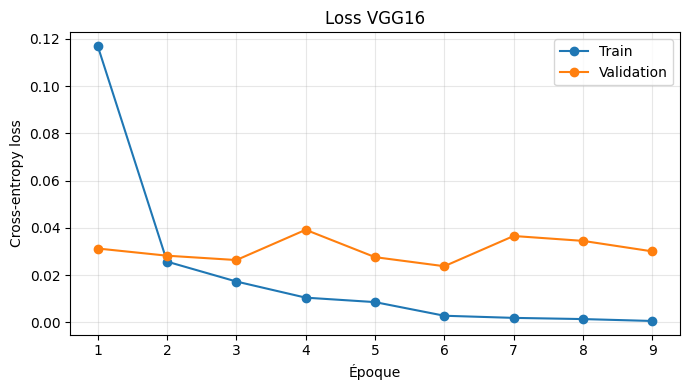

In [9]:
epochs=[r["epoch"] for r in history]
plt.figure(figsize=(7,4))
plt.plot(epochs,[r["train_loss"] for r in history],marker="o",label="Train")
plt.plot(epochs,[r["val_loss"] for r in history],marker="o",label="Validation")
plt.xlabel("Époque"); plt.ylabel("Cross-entropy loss"); plt.title("Loss VGG16")
plt.grid(True,alpha=.3); plt.legend(); plt.tight_layout(); plt.show()

## Test final
La test loss est la cross-entropy moyenne sur les 10 000 images test, qui n’ont pas servi à l’entraînement ni au choix du checkpoint.

In [10]:
from sklearn.metrics import accuracy_score,f1_score,classification_report
model.eval(); total_loss=0.; y_true=[]; y_pred=[]
criterion=nn.CrossEntropyLoss(reduction="sum")
with torch.no_grad():
    for x,y in test_loader:
        x=x.to(device,non_blocking=True); logits=model(x)
        total_loss+=criterion(logits,y.to(device)).item()
        y_pred.extend(logits.argmax(1).cpu().tolist()); y_true.extend(y.tolist())
test_loss=total_loss/len(test_ds)
print(f"Test loss: {test_loss:.4f}")
print(f"Test accuracy: {accuracy_score(y_true,y_pred):.4f}")
print(f"Test F1 macro: {f1_score(y_true,y_pred,average='macro'):.4f}")
print(classification_report(y_true,y_pred,digits=4))

Test loss: 0.0226
Test accuracy: 0.9949
Test F1 macro: 0.9949
              precision    recall  f1-score   support

           0     0.9949    0.9990    0.9969       980
           1     0.9947    0.9965    0.9956      1135
           2     0.9952    0.9961    0.9956      1032
           3     0.9960    0.9980    0.9970      1010
           4     0.9959    0.9878    0.9918       982
           5     0.9944    0.9955    0.9950       892
           6     0.9989    0.9875    0.9932       958
           7     0.9942    0.9942    0.9942      1028
           8     0.9949    1.0000    0.9974       974
           9     0.9901    0.9941    0.9921      1009

    accuracy                         0.9949     10000
   macro avg     0.9949    0.9949    0.9949     10000
weighted avg     0.9949    0.9949    0.9949     10000



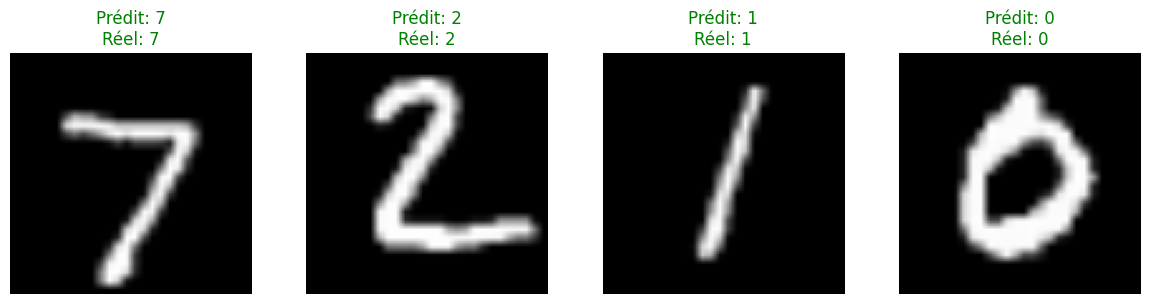

Checkpoint: /kaggle/working/mnist_vgg16_best.pth


In [11]:
xs,ys=next(iter(test_loader))
with torch.no_grad(): preds=model(xs[:4].to(device)).argmax(1).cpu()
fig,axs=plt.subplots(1,4,figsize=(12,3))
for ax,x,y,p in zip(axs,xs[:4],ys[:4],preds):
    ax.imshow((x*std+mean).clamp(0,1).permute(1,2,0))
    ax.set_title(f"Prédit: {p.item()}\nRéel: {y.item()}",color="green" if p.item()==y.item() else "red")
    ax.axis("off")
plt.tight_layout(); plt.show()
print("Checkpoint: /kaggle/working/mnist_vgg16_best.pth")

## Réutiliser le checkpoint
Le meilleur modèle est enregistré dans /kaggle/working/mnist_vgg16_best.pth. Après Save Version, il apparaît dans les sorties Kaggle. Pour refaire une évaluation, reconstruisez la même architecture et chargez ce checkpoint. Les couches gelées, dropout, weight decay et early stopping réduisent le surapprentissage.